In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

RESULTS = Path("../results/phase0")

In [2]:
data = np.load(
    RESULTS / "k562_measured_responses.npz",
    allow_pickle=True,
)

X = data["X"].astype(np.float32)
targets = data["targets"].astype(str)
rna_genes = data["genes"].astype(str)

print("RNA matrix:", X.shape)
print("Targets:", len(targets))
print("RNA features:", len(rna_genes))

RNA matrix: (1641, 7226)
Targets: 1641
RNA features: 7226


In [3]:
fitness = pd.read_csv(
    RESULTS / "k562_gene_fitness.csv"
)

fitness = (
    fitness
    .set_index("gene")
    .loc[targets]
)

y = fitness["k562_gamma"].to_numpy()

print("Fitness:", y.shape)

Fitness: (1641,)


In [4]:
metadata = pd.read_csv(
    RESULTS / "k562_response_metadata.csv"
)

metadata = (
    metadata
    .set_index("gene")
    .loc[targets]
)

n_cells = metadata["n_cells"].to_numpy()

assert len(y) == X.shape[0]
assert len(n_cells) == X.shape[0]

In [5]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

In [6]:
mean_model = DummyRegressor(
    strategy="mean"
)

pred_mean = cross_val_predict(
    mean_model,
    np.zeros((len(y), 1)),
    y,
    cv=cv,
)

In [7]:
X_cells = np.log1p(
    n_cells
).reshape(-1, 1)

cell_model = Pipeline([
    (
        "scale",
        StandardScaler(),
    ),
    (
        "ridge",
        RidgeCV(
            alphas=np.logspace(-4, 4, 17)
        ),
    ),
])

pred_cells = cross_val_predict(
    cell_model,
    X_cells,
    y,
    cv=cv,
)

In [8]:
response_magnitude = np.mean(
    np.abs(X),
    axis=1,
).reshape(-1, 1)

magnitude_model = Pipeline([
    (
        "scale",
        StandardScaler(),
    ),
    (
        "ridge",
        RidgeCV(
            alphas=np.logspace(-4, 4, 17)
        ),
    ),
])

pred_magnitude = cross_val_predict(
    magnitude_model,
    response_magnitude,
    y,
    cv=cv,
)

In [9]:
rna_model = Pipeline([
    (
        "scale",
        StandardScaler(),
    ),
    (
        "pca",
        PCA(
            n_components=100,
            svd_solver="randomized",
            random_state=42,
        ),
    ),
    (
        "ridge",
        RidgeCV(
            alphas=np.logspace(-4, 4, 17)
        ),
    ),
])

In [10]:
pred_rna = cross_val_predict(
    rna_model,
    X,
    y,
    cv=cv,
    n_jobs=1,
)

In [11]:
def evaluate_predictions(name, y_true, y_pred):

    if np.std(y_pred) == 0:
        spearman = np.nan
        pearson = np.nan
    else:
        spearman = spearmanr(
            y_true,
            y_pred,
        ).statistic

        pearson = pearsonr(
            y_true,
            y_pred,
        ).statistic

    return {
        "model": name,
        "spearman_rho": spearman,
        "pearson_r": pearson,
        "r2": r2_score(
            y_true,
            y_pred,
        ),
        "mae": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "rmse": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred,
            )
        ),
    }

In [12]:
results = pd.DataFrame([
    evaluate_predictions(
        "Mean baseline",
        y,
        pred_mean,
    ),
    evaluate_predictions(
        "Cell count only",
        y,
        pred_cells,
    ),
    evaluate_predictions(
        "RNA magnitude only",
        y,
        pred_magnitude,
    ),
    evaluate_predictions(
        "PCA + Ridge",
        y,
        pred_rna,
    ),
])

display(results)

,model,spearman_rho,pearson_r,r2,mae,rmse
0,Mean baseline,-0.100709,-0.108097,-0.006572,0.179715,0.210927
1,Cell count only,0.045223,0.077852,0.005371,0.177916,0.209672
2,RNA magnitude only,0.537432,0.499450,0.249441,0.149003,0.182139
3,PCA + Ridge,0.700177,0.638602,0.407387,0.127554,0.161844


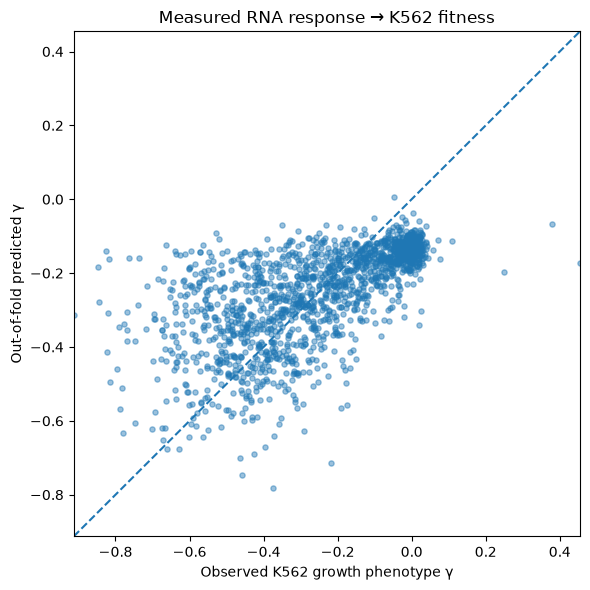

In [13]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y,
    pred_rna,
    s=14,
    alpha=0.45,
)

plt.xlabel("Observed K562 growth phenotype γ")
plt.ylabel("Out-of-fold predicted γ")
plt.title("Measured RNA response → K562 fitness")

limits = [
    min(y.min(), pred_rna.min()),
    max(y.max(), pred_rna.max()),
]

plt.plot(
    limits,
    limits,
    linestyle="--",
)

plt.xlim(limits)
plt.ylim(limits)

plt.tight_layout()
plt.show()

In [14]:
prediction_table = pd.DataFrame({
    "gene": targets,
    "observed_gamma": y,
    "n_cells": n_cells,
    "pred_mean": pred_mean,
    "pred_cell_count": pred_cells,
    "pred_rna_magnitude": pred_magnitude,
    "pred_pca_ridge": pred_rna,
})

prediction_table.to_csv(
    RESULTS / "k562_fitness_predictions.csv",
    index=False,
)

results.to_csv(
    RESULTS / "k562_fitness_model_metrics.csv",
    index=False,
)

In [15]:
rna_gene_to_idx = {
    gene: idx
    for idx, gene in enumerate(rna_genes)
}

measured_targets = [
    gene
    for gene in targets
    if gene in rna_gene_to_idx
]

print("Total perturbations:", len(targets))
print("Target genes present in RNA features:", len(measured_targets))
print(
    "Fraction:",
    len(measured_targets) / len(targets)
)

Total perturbations: 1641
Target genes present in RNA features: 1415
Fraction: 0.862279098110908


In [16]:
X_masked = X.copy()

In [17]:
n_masked = 0

for row_idx, target in enumerate(targets):

    col_idx = rna_gene_to_idx.get(target)

    if col_idx is not None:
        X_masked[row_idx, col_idx] = 0.0
        n_masked += 1

print("Target-expression values masked:", n_masked)

Target-expression values masked: 1415


In [18]:
pred_rna_masked = cross_val_predict(
    rna_model,
    X_masked,
    y,
    cv=cv,
    n_jobs=1,
)

In [19]:
masked_result = evaluate_predictions(
    "PCA + Ridge (target masked)",
    y,
    pred_rna_masked,
)

pd.DataFrame([
    evaluate_predictions(
        "RNA magnitude only",
        y,
        pred_magnitude,
    ),
    evaluate_predictions(
        "PCA + Ridge",
        y,
        pred_rna,
    ),
    masked_result,
])

,model,spearman_rho,pearson_r,r2,mae,rmse
0,RNA magnitude only,0.537432,0.499450,0.249441,0.149003,0.182139
1,PCA + Ridge,0.700177,0.638602,0.407387,0.127554,0.161844
2,PCA + Ridge (target masked),0.699898,0.638748,0.407594,0.127563,0.161815


In [20]:
seeds = [
    11,
    22,
    33,
    44,
    55,
]

stability_rows = []

for seed in seeds:

    cv_seed = KFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    pred = cross_val_predict(
        rna_model,
        X_masked,
        y,
        cv=cv_seed,
        n_jobs=1,
    )

    stability_rows.append({
        "seed": seed,
        "spearman_rho": spearmanr(
            y,
            pred,
        ).statistic,
        "pearson_r": pearsonr(
            y,
            pred,
        ).statistic,
        "r2": r2_score(
            y,
            pred,
        ),
    })

stability = pd.DataFrame(
    stability_rows
)

display(stability)

,seed,spearman_rho,pearson_r,r2
0,11,0.707211,0.648094,0.418901
1,22,0.705562,0.645804,0.416318
2,33,0.704298,0.644328,0.414246
3,44,0.700096,0.643016,0.412831
4,55,0.702103,0.640032,0.409097


In [23]:
rng = np.random.default_rng(42)

y_shuffled = rng.permutation(y)

pred_shuffled = cross_val_predict(
    rna_model,
    X_masked,
    y_shuffled,
    cv=cv,
    n_jobs=1,
)

shuffle_result = evaluate_predictions(
    "PCA + Ridge (shuffled labels)",
    y_shuffled,
    pred_shuffled,
)

pd.DataFrame([
    evaluate_predictions(
        "PCA + Ridge (real labels)",
        y,
        pred_rna_masked,
    ),
    shuffle_result,
])

,model,spearman_rho,pearson_r,r2,mae,rmse
0,PCA + Ridge (real labels),0.699898,0.638748,0.407594,0.127563,0.161815
1,PCA + Ridge (shuffled labels),0.043326,0.025509,-0.010791,0.179533,0.211369


In [22]:
robustness_results = pd.DataFrame([
    evaluate_predictions(
        "RNA magnitude only",
        y,
        pred_magnitude,
    ),
    evaluate_predictions(
        "PCA + Ridge",
        y,
        pred_rna,
    ),
    evaluate_predictions(
        "PCA + Ridge (target masked)",
        y,
        pred_rna_masked,
    ),
    shuffle_result,
])

robustness_results.to_csv(
    RESULTS / "k562_robustness_metrics.csv",
    index=False,
)

stability.to_csv(
    RESULTS / "k562_cv_stability.csv",
    index=False,
)

In [24]:
robustness_results.to_csv(
    RESULTS / "k562_robustness_metrics.csv",
    index=False
)

stability.to_csv(
    RESULTS / "k562_cv_stability.csv",
    index=False
)